# Tugas 1
Klasifikasi Suara `male` / `female` dengan kNN

**Dataset:** `voice.csv` — 3.168 sampel suara (1.584 male, 1.584 female) dengan 20 fitur akustik (`meanfreq`, `sd`, `median`, `Q25`, `Q75`, `IQR`, `skew`, `kurt`, `sp.ent`, `sfm`, `mode`, `centroid`, `meanfun`, `minfun`, `maxfun`, `meandom`, `mindom`, `maxdom`, `dfrange`, `modindx`) dan label `label`.

**Yang dikerjakan:**

1. Model kNN untuk mengklasifikasikan `male` / `female`.
2. Percobaan mencari fitur yang paling optimal.
3. Menentukan nilai $k$ terbaik beserta grafik analisis dan alasannya.

### Langkah 1 - Import Library & Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set(style='whitegrid')

df = pd.read_csv('voice.csv')
print('Ukuran data:', df.shape)
df.head()

Ukuran data: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


### Langkah 2 - Eksplorasi Data

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   str    
dtypes:

In [3]:
print(df['label'].value_counts())
print()
print('Missing values:', df.isna().sum().sum())
print('Duplikat     :', df.duplicated().sum())

label
male      1584
female    1584
Name: count, dtype: int64

Missing values: 0
Duplikat     : 2


Distribusi kelas **seimbang** (1.584 vs 1.584), sehingga akurasi dapat dipakai sebagai metrik utama. Terdapat sejumlah baris duplikat — akan dibuang agar tidak terjadi *data leakage* antara data latih dan uji.

In [4]:
# Hapus duplikat
sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplikat dibuang: {sebelum - len(df)} baris -> sisa {len(df)} baris')

Duplikat dibuang: 2 baris -> sisa 3166 baris


### Langkah 3 - Encoding Label & Split Data

In [5]:
X = df.drop(columns=['label'])
y = df['label'].map({'male': 1, 'female': 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)
print('Proporsi kelas di data uji:', y_test.value_counts(normalize=True).round(3).to_dict())

Data latih: (2532, 20) | Data uji: (634, 20)
Proporsi kelas di data uji: {0: 0.5, 1: 0.5}


### Langkah 4 - Baseline: Semua Fitur
Latih kNN dengan 20 fitur untuk melihat performa awal.

In [6]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

knn_all = KNeighborsClassifier(n_neighbors=5)
knn_all.fit(X_train_sc, y_train)
acc_all = accuracy_score(y_test, knn_all.predict(X_test_sc))
print(f'Akurasi baseline (20 fitur, k=5): {acc_all:.4f}')

Akurasi baseline (20 fitur, k=5): 0.9763


### Langkah 5 - Seleksi Fitur
Fitur diberi skor dengan **ANOVA F-test** (`f_classif`). Skor tinggi berarti fitur tersebut paling membedakan `male` dan `female`.

In [7]:
selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_train_sc, y_train)

skor = pd.DataFrame({
    'Fitur': X.columns,
    'F-score': selector.scores_,
    'p-value': selector.pvalues_,
}).sort_values('F-score', ascending=False)

skor

,Fitur,F-score,p-value
12,meanfun,5773.984670,0.000000e+00
5,IQR,1556.663014,9.452319e-266
3,Q25,880.806936,2.382397e-166
8,sp.ent,769.766289,3.820075e-148
1,sd,734.534714,3.070284e-142
9,sfm,353.812858,5.544042e-74
0,meanfreq,317.129578,6.278759e-67
11,centroid,317.129578,6.278759e-67
2,median,213.593271,1.681499e-46
16,mindom,97.432241,1.417381e-22


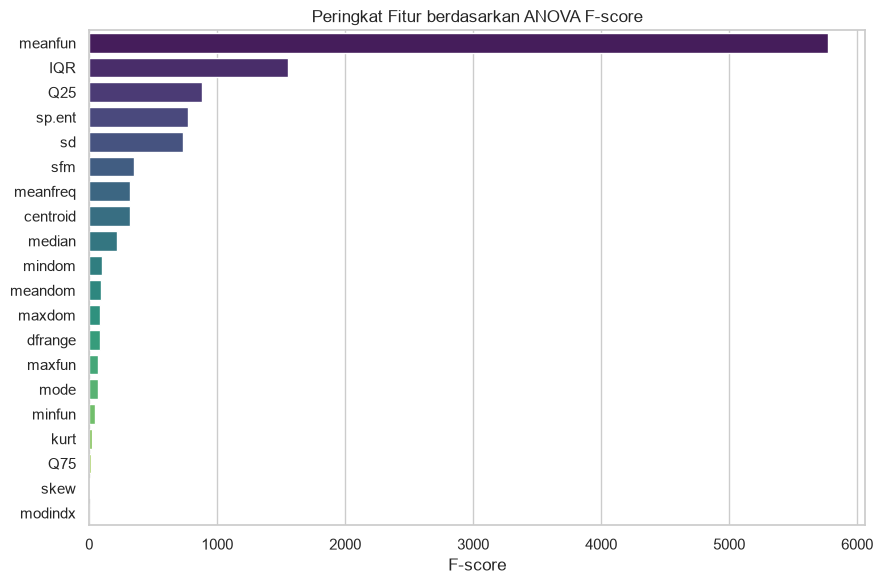

In [8]:
plt.figure(figsize=(9, 6))
sns.barplot(data=skor, x='F-score', y='Fitur', hue='Fitur', legend=False, palette='viridis')
plt.title('Peringkat Fitur berdasarkan ANOVA F-score')
plt.xlabel('F-score')
plt.ylabel('')
plt.tight_layout()
plt.show()

### Langkah 6 - Percobaan Jumlah Fitur
Uji $n$ fitur terbaik dari 1 sampai 20 (seleksi di-*fit* pada data latih saja, lalu diterapkan ke data uji). Cari titik dengan akurasi tertinggi sekaligus jumlah fitur paling sedikit.

In [9]:
hasil = []
for n in range(1, X_train_sc.shape[1] + 1):
    sel = SelectKBest(score_func=f_classif, k=n)
    Xtr = sel.fit_transform(X_train_sc, y_train)
    Xte = sel.transform(X_test_sc)

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(Xtr, y_train)
    hasil.append({
        'n_fitur': n,
        'akurasi_test': accuracy_score(y_test, model.predict(Xte)),
        'akurasi_train': accuracy_score(y_train, model.predict(Xtr)),
    })

hasil_df = pd.DataFrame(hasil)
hasil_df

,n_fitur,akurasi_test,akurasi_train
0,1,0.943218,0.960506
1,2,0.971609,0.976303
2,3,0.976341,0.978673
3,4,0.968454,0.982227
4,5,0.977918,0.985782
5,6,0.982650,0.984202
6,7,0.979495,0.985387
7,8,0.977918,0.984992
8,9,0.976341,0.987362
9,10,0.981073,0.985387


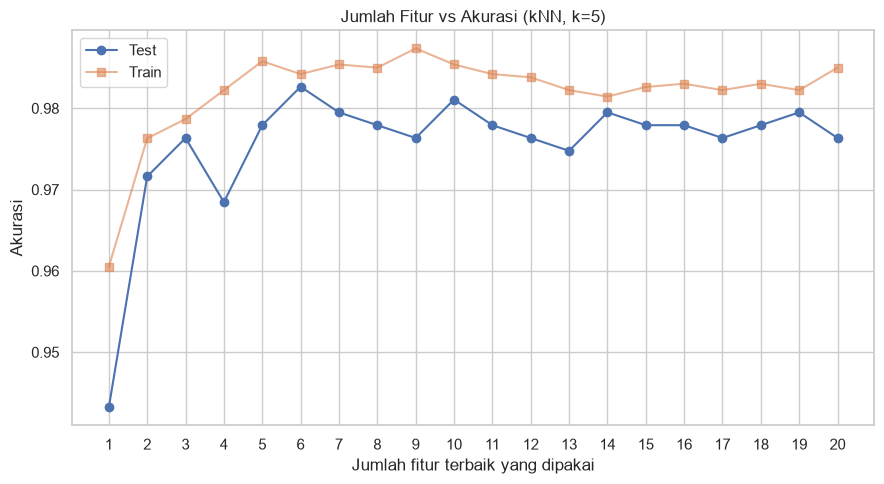

Jumlah fitur terbaik (akurasi test tertinggi): 6
Akurasi: 0.9826


In [10]:
plt.figure(figsize=(9, 5))
plt.plot(hasil_df['n_fitur'], hasil_df['akurasi_test'], marker='o', label='Test')
plt.plot(hasil_df['n_fitur'], hasil_df['akurasi_train'], marker='s', label='Train', alpha=0.6)
plt.title('Jumlah Fitur vs Akurasi (kNN, k=5)')
plt.xlabel('Jumlah fitur terbaik yang dipakai')
plt.ylabel('Akurasi')
plt.xticks(hasil_df['n_fitur'])
plt.legend()
plt.tight_layout()
plt.show()

best_n = int(hasil_df.loc[hasil_df['akurasi_test'].idxmax(), 'n_fitur'])
print(f'Jumlah fitur terbaik (akurasi test tertinggi): {best_n}')
print(f"Akurasi: {hasil_df['akurasi_test'].max():.4f}")

### Langkah 7 - Menentukan Nilai k Terbaik
Dengan subset fitur terpilih, sapu nilai $k$ dari 1 sampai 30 dan cari akurasi uji tertinggi.

Fitur terpilih: ['sd', 'Q25', 'IQR', 'sp.ent', 'sfm', 'meanfun']


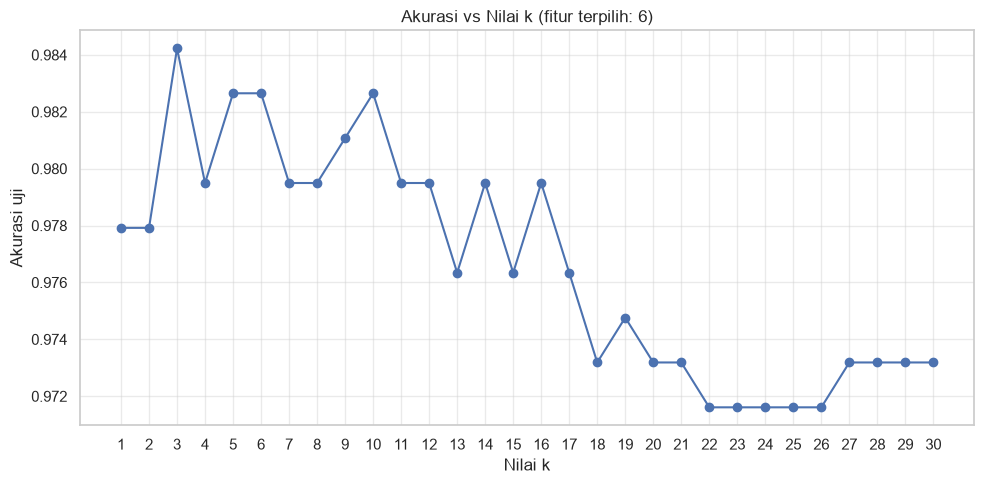

Nilai k terbaik: 3 (akurasi 0.9842)


In [11]:
sel_final = SelectKBest(score_func=f_classif, k=best_n)
X_train_best = sel_final.fit_transform(X_train_sc, y_train)
X_test_best = sel_final.transform(X_test_sc)

fitur_terpilih = [f for f, keep in zip(X.columns, sel_final.get_support()) if keep]
print('Fitur terpilih:', fitur_terpilih)

ks = range(1, 31)
acc_k = []
for k in ks:
    m = KNeighborsClassifier(n_neighbors=k)
    m.fit(X_train_best, y_train)
    acc_k.append(accuracy_score(y_test, m.predict(X_test_best)))

plt.figure(figsize=(10, 5))
plt.plot(list(ks), acc_k, marker='o')
plt.title(f'Akurasi vs Nilai k (fitur terpilih: {best_n})')
plt.xlabel('Nilai k')
plt.ylabel('Akurasi uji')
plt.xticks(list(ks))
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

best_k = list(ks)[int(np.argmax(acc_k))]
print(f'Nilai k terbaik: {best_k} (akurasi {max(acc_k):.4f})')

### Langkah 8 - Evaluasi Model Final

In [12]:
final = KNeighborsClassifier(n_neighbors=best_k)
final.fit(X_train_best, y_train)
y_pred = final.predict(X_test_best)

print(f'Model final: {best_n} fitur, k={best_k}')
print(f'Akurasi test: {accuracy_score(y_test, y_pred):.4f}\n')
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred))
print('\nLaporan Klasifikasi:\n', classification_report(y_test, y_pred, target_names=['female', 'male']))

Model final: 6 fitur, k=3
Akurasi test: 0.9842

Confusion Matrix:
 [[313   4]
 [  6 311]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.99      0.98       317
        male       0.99      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



In [13]:
# Ringkasan perbandingan
ringkas = pd.DataFrame([
    {'Konfigurasi': 'Semua fitur (20), k=5', 'Akurasi': acc_all},
    {'Konfigurasi': f'{best_n} fitur terbaik, k=5', 'Akurasi': hasil_df['akurasi_test'].max()},
    {'Konfigurasi': f'{best_n} fitur terbaik, k={best_k}', 'Akurasi': max(acc_k)},
])
ringkas['Akurasi'] = ringkas['Akurasi'].round(4)
ringkas

,Konfigurasi,Akurasi
0,"Semua fitur (20), k=5",0.9763
1,"6 fitur terbaik, k=5",0.9826
2,"6 fitur terbaik, k=3",0.9842


### Analisis dan Kesimpulan

**1) Model kNN untuk `male`/`female`** — berhasil dibuat setelah data dibersihkan dari duplikat, label di-encode (male=1, female=0), fitur distandarisasi, dan data dibagi 80:20 secara *stratified*.

**2) Fitur paling optimal** — berdasarkan ANOVA F-test, lima fitur teratas adalah **`meanfun`** (F ≈ 5774), **`IQR`** (≈ 1557), **`Q25`** (≈ 881), **`sp.ent`** (≈ 770), dan **`sd`** (≈ 735). `meanfun` (frekuensi fundamental rata-rata) jauh paling dominan — masuk akal secara fisiologis karena pita suara pria lebih tebal sehingga frekuensi dasarnya jauh lebih rendah. Dengan hanya **6 fitur teratas** (`meanfun`, `IQR`, `Q25`, `sp.ent`, `sfm`, `sd`), akurasi uji **0,9826** — bahkan sedikit lebih baik daripada memakai seluruh 20 fitur (**0,9763**). Artinya banyak fitur lain redundan.

**3) Nilai $k$ terbaik** — dari sweep $k=1\ldots30$ pada 6 fitur terpilih, akurasi tertinggi dicapai pada **$k = 3$ (0,9842)**, disusul $k=5,6,10$ (0,9826). Kurva relatif datar untuk $k \leq 15$ lalu perlahan menurun pada $k \geq 18$ (≈ 0,972). Nilai $k$ kecil membuat model sensitif terhadap *noise*, sedangkan $k$ terlalu besar menarik tetangga dari kelas lain.

**Ringkasan akurasi:** baseline 20 fitur, $k=5$ → **0,9763**; 6 fitur terbaik, $k=5$ → **0,9826**; 6 fitur terbaik, $k=3$ → **0,9842**.

**Praktik terbaik yang diterapkan:**

* Seleksi fitur dan standardisasi di-*fit* **hanya pada data latih** (mencegah *data leakage*).
* Duplikat dibuang sebelum split agar data uji benar-benar asing bagi model.
* `stratify=y` menjaga proporsi kelas tetap seimbang di kedua subset.
* Akurasi dilaporkan bersama confusion matrix dan precision/recall, bukan akurasi saja.